
# Predicting 30 Day Hospital Readmission with Gradient Boosting

This notebook walks through the full process of building a model that
predicts whether a patient will be readmitted to the hospital within 30
days of discharge. We use full MIMIC III data and XGBoost, and we spend
a lot of time on one specific problem that shows up constantly in real
healthcare data: the outcome we care about is rare. Only about 6 out of
every 100 patients in our data get readmitted within 30 days. Learning
how to handle that imbalance correctly is the main lesson of this
notebook, not just getting a model to run.

We also run a small feature selection exercise, compare performance
across every feature tier, and try a few engineered features to see if
they help. Some of them do not, and we explain why.



## 1. Problem statement

Hospitals in the United States are financially penalized by Medicare if
too many of their patients get readmitted within 30 days of discharge,
under a policy called the Hospital Readmissions Reduction Program. This
is not a small deal. A hospital can lose up to 3 percent of its entire
Medicare reimbursement over this.

In practice, hospitals try to catch high risk patients before they are
discharged, so they can send a few of them extra help, like a follow up
phone call or an earlier check in appointment. That only works if you
can tell, ahead of time, who is actually at risk. That is the problem we
are solving here: given everything we know about a patient at the time
they leave the hospital, can we predict whether they will be back within
30 days?



## 2. Building the dataset

We are using the full MIMIC III database, not the smaller demo version.
We pull from seven tables: PATIENTS, ADMISSIONS, DIAGNOSES_ICD,
D_ICD_DIAGNOSES, ICUSTAYS, DRGCODES, and CPTEVENTS, plus a lactate lab
extract from LABEVENTS.

Before we can build any features, we need to decide who actually belongs
in this study. We make two decisions here. First, we drop NEWBORN
admissions, because a newborn's hospital stay is not really comparable
to an adult being admitted and discharged. Second, we drop any admission
that ended in death, since a patient who died obviously cannot come back
within 30 days.


In [1]:

import sys
from pathlib import Path
sys.path.insert(0, "..")
import numpy as np
import pandas as pd

DATA_DIR = Path("../data")

admissions = pd.read_csv(
    DATA_DIR / "ADMISSIONS.csv.gz",
    parse_dates=["ADMITTIME", "DISCHTIME"],
)[["SUBJECT_ID", "HADM_ID", "ADMITTIME", "DISCHTIME", "ADMISSION_TYPE",
   "HOSPITAL_EXPIRE_FLAG", "INSURANCE", "MARITAL_STATUS", "ETHNICITY"]]

print(f"Admissions before any filtering: {len(admissions)}")

cohort = admissions[
    (admissions["ADMISSION_TYPE"] != "NEWBORN") & (admissions["HOSPITAL_EXPIRE_FLAG"] == 0)
].copy()
cohort = cohort.sort_values(["SUBJECT_ID", "ADMITTIME"])

print(f"Eligible admissions after dropping NEWBORN and in hospital deaths: {len(cohort)}")


Admissions before any filtering: 58976
Eligible admissions after dropping NEWBORN and in hospital deaths: 45321



Now we build the label. For each eligible admission, we look at the same
patient's next admission, whatever type it is, and check whether it
started within 30 days of this admission's discharge. This is a classic
self join pattern done with a group by and a shift instead of an actual
SQL join, since we are working in pandas here, not SQL.


In [2]:

cohort["NEXT_ADMITTIME"] = cohort.groupby("SUBJECT_ID")["ADMITTIME"].shift(-1)
days_to_next = (cohort["NEXT_ADMITTIME"] - cohort["DISCHTIME"]).dt.total_seconds() / 86400
cohort["READMIT_30D"] = ((days_to_next >= 0) & (days_to_next <= 30)).astype(int)
cohort["HOSPITAL_LOS_DAYS"] = (cohort["DISCHTIME"] - cohort["ADMITTIME"]).dt.total_seconds() / 86400

print(f"Readmitted within 30 days: {cohort['READMIT_30D'].sum()} out of {len(cohort)}")
print(f"That is {100 * cohort['READMIT_30D'].mean():.2f} percent of the cohort")


Readmitted within 30 days: 2702 out of 45321
That is 5.96 percent of the cohort



Now we add features. We are building these in four groups, called tiers,
because later on we want to test how much each group actually adds to
the model, instead of just throwing everything in at once.

Tier 1 is basic demographics and admin fields, things we know about
every patient on day one with no clinical interpretation needed at all.


In [3]:

patients = pd.read_csv(DATA_DIR / "PATIENTS.csv.gz", parse_dates=["DOB"])[["SUBJECT_ID", "GENDER", "DOB"]]
cohort = cohort.merge(patients, on="SUBJECT_ID", how="left")

age_years = (cohort["ADMITTIME"] - cohort["DOB"]).dt.days / 365.25
# MIMIC shifts the birth date of anyone over 89 so they look about 300
# years old, as a way to de-identify them. We cap those at 91.4, which is
# the usual convention in MIMIC based research, instead of letting a fake
# 300 year old patient distort every age based calculation.
cohort["AGE"] = np.where(age_years > 89, 91.4, age_years)

print(cohort[["AGE", "GENDER", "INSURANCE", "MARITAL_STATUS", "ETHNICITY", "ADMISSION_TYPE"]].describe(include="all").T)


                  count unique        top   freq       mean        std  min  \
AGE             45321.0    NaN        NaN    NaN  62.795381  17.931685  0.0   
GENDER            45321      2          M  25588        NaN        NaN  NaN   
INSURANCE         45321      5   Medicare  24309        NaN        NaN  NaN   
MARITAL_STATUS    43346      7    MARRIED  21626        NaN        NaN  NaN   
ETHNICITY         45321     41      WHITE  32212        NaN        NaN  NaN   
ADMISSION_TYPE    45321      3  EMERGENCY  36637        NaN        NaN  NaN   

                      25%        50%        75%   max  
AGE             51.619439  64.495551  76.788501  91.4  
GENDER                NaN        NaN        NaN   NaN  
INSURANCE             NaN        NaN        NaN   NaN  
MARITAL_STATUS        NaN        NaN        NaN   NaN  
ETHNICITY             NaN        NaN        NaN   NaN  
ADMISSION_TYPE        NaN        NaN        NaN   NaN  



Tier 2 adds clinical context: what was this patient actually diagnosed
with, and how severe was it. The primary diagnosis chapter comes from
mapping the ICD9 code to one of the standard diagnostic chapters, since
the MIMIC tables do not store that chapter directly. DRG severity is a 1
to 4 score that comes from the APR DRG coding system.


In [4]:

ICD9_CHAPTERS = [
    (1, 139, "Infectious & Parasitic"), (140, 239, "Neoplasms"),
    (240, 279, "Endocrine/Metabolic"), (280, 289, "Blood & Blood-forming"),
    (290, 319, "Mental Disorders"), (320, 389, "Nervous System"),
    (390, 459, "Circulatory System"), (460, 519, "Respiratory System"),
    (520, 579, "Digestive System"), (580, 629, "Genitourinary System"),
    (630, 679, "Pregnancy/Childbirth"), (680, 709, "Skin & Subcutaneous"),
    (710, 739, "Musculoskeletal"), (740, 759, "Congenital Anomalies"),
    (760, 779, "Perinatal Conditions"), (780, 799, "Symptoms & Ill-defined"),
    (800, 999, "Injury & Poisoning"),
]

def icd9_to_chapter(code_str):
    if pd.isna(code_str):
        return "Unknown"
    code_str = str(code_str).strip()
    if code_str.startswith("V"):
        return "Supplementary (V-codes)"
    if code_str.startswith("E"):
        return "External Causes (E-codes)"
    try:
        prefix = int(code_str[:3])
    except ValueError:
        return "Unknown"
    for low, high, label in ICD9_CHAPTERS:
        if low <= prefix <= high:
            return label
    return "Unknown"

dx = pd.read_csv(DATA_DIR / "DIAGNOSES_ICD.csv.gz", dtype={"ICD9_CODE": str})
primary_dx = dx[dx["SEQ_NUM"] == 1][["SUBJECT_ID", "HADM_ID", "ICD9_CODE"]].copy()
primary_dx["CHAPTER"] = primary_dx["ICD9_CODE"].apply(icd9_to_chapter)
cohort = cohort.merge(primary_dx[["HADM_ID", "CHAPTER"]], on="HADM_ID", how="left")

drg = pd.read_csv(DATA_DIR / "DRGCODES.csv.gz")
# The DRG_TYPE column has a trailing space in this export, "APR " instead
# of "APR". We strip it before filtering, otherwise this filter silently
# matches nothing and every severity score comes back empty.
drg["DRG_TYPE"] = drg["DRG_TYPE"].str.strip()
apr = drg[drg["DRG_TYPE"] == "APR"].dropna(subset=["DRG_SEVERITY"])
drg_agg = apr.groupby("HADM_ID").agg(
    DRG_SEVERITY=("DRG_SEVERITY", "max"), DRG_MORTALITY=("DRG_MORTALITY", "max")
).reset_index()
cohort = cohort.merge(drg_agg, on="HADM_ID", how="left")

print(f"Chapter coverage: {cohort['CHAPTER'].notna().mean():.1%}")
print(f"DRG severity coverage: {cohort['DRG_SEVERITY'].notna().mean():.1%}")


Chapter coverage: 100.0%
DRG severity coverage: 71.1%



Tier 3 adds care intensity: how much was actually done for this patient
during the stay. ICU time, number of procedures, and the highest lactate
lab value we could find, since lactate is commonly used in practice as a
marker of how sick someone is.


In [5]:

icu = pd.read_csv(DATA_DIR / "ICUSTAYS.csv.gz")
icu_agg = icu.groupby("HADM_ID").agg(ICU_LOS=("LOS", "sum"), ICU_STAYS=("ICUSTAY_ID", "count")).reset_index()
cohort = cohort.merge(icu_agg, on="HADM_ID", how="left")
cohort["ICU_LOS"] = cohort["ICU_LOS"].fillna(0)
cohort["HAD_ICU_STAY"] = (cohort["ICU_STAYS"].fillna(0) > 0).astype(int)

cpt = pd.read_csv(DATA_DIR / "CPTEVENTS.csv.gz", usecols=["HADM_ID", "CPT_CD"], dtype={"CPT_CD": str})
cpt_agg = cpt.groupby("HADM_ID").agg(PROCEDURE_COUNT=("CPT_CD", "count")).reset_index()
cohort = cohort.merge(cpt_agg, on="HADM_ID", how="left")
cohort["PROCEDURE_COUNT"] = cohort["PROCEDURE_COUNT"].fillna(0)

lactate = pd.read_csv(DATA_DIR / "LABEVENTS_LACTATE.csv.gz")
lac_agg = lactate.groupby("HADM_ID").agg(MAX_LACTATE=("VALUENUM", "max")).reset_index()
cohort = cohort.merge(lac_agg, on="HADM_ID", how="left")
cohort["HAD_LACTATE_TEST"] = cohort["MAX_LACTATE"].notna().astype(int)
cohort["MAX_LACTATE"] = cohort["MAX_LACTATE"].fillna(cohort["MAX_LACTATE"].median())

print(f"Had an ICU stay: {cohort['HAD_ICU_STAY'].mean():.1%}")
print(f"Had a lactate test: {cohort['HAD_LACTATE_TEST'].mean():.1%}")


Had an ICU stay: 97.7%
Had a lactate test: 64.9%



Tier 4 adds one feature: how many times has this patient been admitted
before. This comes from a well known idea in readmission research, that
past hospital use is one of the strongest predictors of future hospital
use. We compute it from the full admissions table, not just our eligible
cohort, so we do not undercount someone's real history just because one
of their earlier visits happened to be a NEWBORN admission that got
excluded above.


In [6]:

all_adm = pd.read_csv(DATA_DIR / "ADMISSIONS.csv.gz", parse_dates=["ADMITTIME"])
all_adm = all_adm[["SUBJECT_ID", "HADM_ID", "ADMITTIME"]].sort_values(["SUBJECT_ID", "ADMITTIME"])
all_adm["PRIOR_ADMISSION_COUNT"] = all_adm.groupby("SUBJECT_ID").cumcount()
cohort = cohort.merge(all_adm[["HADM_ID", "PRIOR_ADMISSION_COUNT"]], on="HADM_ID", how="left")

print(cohort["PRIOR_ADMISSION_COUNT"].describe())
cohort.to_pickle(DATA_DIR / "cohort.pkl")


count    45321.000000
mean         0.524304
std          1.695690
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         41.000000
Name: PRIOR_ADMISSION_COUNT, dtype: float64



## 3. Train and test split

Before we train anything, we split the data and take a look at what we
are actually working with. This matters a lot here because the class we
care about, readmitted, is rare. If we are not careful, a random split
could leave our test set with almost no positive examples in it, which
would make every metric we calculate afterward meaningless.


In [7]:

from sklearn.model_selection import train_test_split

TIER_1 = ["AGE", "GENDER", "INSURANCE", "MARITAL_STATUS", "ETHNICITY", "ADMISSION_TYPE"]
TIER_2 = TIER_1 + ["CHAPTER", "DRG_SEVERITY", "DRG_MORTALITY"]
TIER_3 = TIER_2 + ["ICU_LOS", "HAD_ICU_STAY", "HOSPITAL_LOS_DAYS", "PROCEDURE_COUNT", "MAX_LACTATE", "HAD_LACTATE_TEST"]
TIER_4 = TIER_3 + ["PRIOR_ADMISSION_COUNT"]

CATEGORICAL_COLS = ["GENDER", "INSURANCE", "MARITAL_STATUS", "ETHNICITY", "ADMISSION_TYPE", "CHAPTER"]

y = cohort["READMIT_30D"]
X_full = pd.get_dummies(cohort[TIER_4], columns=CATEGORICAL_COLS, dummy_na=True)

X_train, X_test, y_train, y_test = train_test_split(X_full, y, test_size=0.25, stratify=y, random_state=42)

print(f"Training rows: {len(X_train)}, test rows: {len(X_test)}")
print(f"Features after one hot encoding: {X_full.shape[1]}")
print(f"Positive cases in training set: {y_train.sum()} ({100*y_train.mean():.2f} percent)")
print(f"Positive cases in test set: {y_test.sum()} ({100*y_test.mean():.2f} percent)")


Training rows: 33990, test rows: 11331
Features after one hot encoding: 92
Positive cases in training set: 2026 (5.96 percent)
Positive cases in test set: 676 (5.97 percent)



Both splits land close to 6 percent positive, which is what a stratified
split is supposed to guarantee. Our test set still has over 600 positive
cases in it, which is enough to get a stable read on performance.

Before training anything, here is what we expect going in. We think
diagnosis and severity will matter a lot, since how sick someone is
should reasonably predict whether they end up back in the hospital. We
are less sure about the raw care intensity numbers, ICU time and
procedure count, since those might just be restating how severe the case
was rather than adding anything new. And based on outside research, we
expect prior admission count to matter more than people might assume,
since past hospital use tends to be one of the strongest predictors of
future hospital use in this kind of study.



## 4. Looking at the data before modeling

It helps to actually look at data types and missing values before
building anything. XGBoost can handle missing values on its own, but it
is still worth knowing where they are and why.


In [8]:

print(cohort[TIER_4].dtypes)
print()
print("Missing value percentage by column:")
print((cohort[TIER_4].isna().mean() * 100).round(1).sort_values(ascending=False))


AGE                      float64
GENDER                       str
INSURANCE                    str
MARITAL_STATUS               str
ETHNICITY                    str
ADMISSION_TYPE               str
CHAPTER                      str
DRG_SEVERITY             float64
DRG_MORTALITY            float64
ICU_LOS                  float64
HAD_ICU_STAY               int64
HOSPITAL_LOS_DAYS        float64
PROCEDURE_COUNT          float64
MAX_LACTATE              float64
HAD_LACTATE_TEST           int64
PRIOR_ADMISSION_COUNT      int64
dtype: object

Missing value percentage by column:
DRG_SEVERITY             28.9
DRG_MORTALITY            28.9
MARITAL_STATUS            4.4
AGE                       0.0
GENDER                    0.0
INSURANCE                 0.0
ETHNICITY                 0.0
ADMISSION_TYPE            0.0
CHAPTER                   0.0
ICU_LOS                   0.0
HAD_ICU_STAY              0.0
HOSPITAL_LOS_DAYS         0.0
PROCEDURE_COUNT           0.0
MAX_LACTATE               0.0
H


DRG severity is missing for about 29 percent of admissions, since only
one specific DRG coding type actually carries a severity score. Lactate
is missing even more often, since not every patient gets that lab drawn.
These are not data quality problems, they reflect real differences in
what care a patient received.

One other thing worth checking before we one hot encode anything is how
many distinct values each categorical column has. A column with a lot of
rare categories, like ethnicity, is going to blow up into a lot of
sparse columns once we encode it, and most of those columns will end up
carrying almost no signal.


In [9]:

for col in CATEGORICAL_COLS:
    print(f"{col}: {cohort[col].nunique()} distinct values")


GENDER: 2 distinct values
INSURANCE: 5 distinct values
MARITAL_STATUS: 7 distinct values
ETHNICITY: 41 distinct values
ADMISSION_TYPE: 3 distinct values
CHAPTER: 18 distinct values



## 5. Feature selection

So far we picked features in four tiers based on what category of
information they represent. That tells us whether a group of features
helps, but it does not tell us which individual features inside a group
are actually doing the work. For that we need to train a model first and
then look at which features it actually relied on.

We will come back to this after training the main model, since feature
importance is something you get out of a trained model, not something
you can calculate ahead of time.



## 6. What is gradient boosting

A single decision tree is usually a weak predictor on its own. Gradient
boosting works by training a long sequence of small trees, where each new
tree is trained specifically to correct the mistakes the previous trees
were still making. The final prediction adds up the contributions of
every tree in the sequence.

XGBoost is a popular, fast implementation of this idea. We are using it
here for a few practical reasons. It handles missing values on its own,
it does not require feature scaling, and it tends to perform well on
tabular data like ours without a lot of tuning.



## 7. Handling class imbalance

This is the main lesson of the whole notebook, so we are going to slow
down here instead of rushing through it.

Our positive class, readmitted, is only about 6 percent of the data.
Let's actually look at that split before doing anything about it.


READMIT_30D
0    31964
1     2026
Name: count, dtype: int64


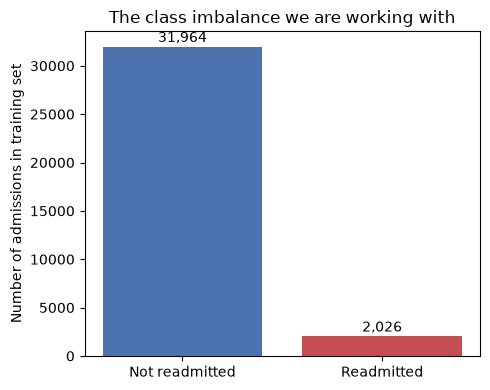

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

class_counts = y_train.value_counts()
print(class_counts)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Not readmitted", "Readmitted"], class_counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 500, f"{v:,}", ha="center")
ax.set_ylabel("Number of admissions in training set")
ax.set_title("The class imbalance we are working with")
plt.tight_layout()
plt.savefig("figures/class_balance.png", dpi=150)
plt.show()



Now let's see what happens if we just ignore this and train a model the
normal way, with no adjustment for the imbalance at all.


In [11]:

from xgboost import XGBClassifier

model_naive = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    eval_metric="logloss", random_state=42,
)
model_naive.fit(X_train, y_train)

naive_preds = model_naive.predict(X_test)
naive_proba = model_naive.predict_proba(X_test)[:, 1]

from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix
print(f"Accuracy: {accuracy_score(y_test, naive_preds):.4f}")
print(f"Precision on the readmitted class: {precision_score(y_test, naive_preds):.4f}")
print(f"Recall on the readmitted class: {recall_score(y_test, naive_preds):.4f}")
print(f"Readmissions actually caught: {((naive_preds == 1) & (y_test == 1)).sum()} out of {y_test.sum()}")


Accuracy: 0.9410
Precision on the readmitted class: 0.7333
Recall on the readmitted class: 0.0163
Readmissions actually caught: 11 out of 676



Look closely at that last line. The accuracy number looks fine, arguably
good, but the model is barely predicting the positive class at all. It
learned that the safest way to minimize error is to almost always guess
no readmission, since that is right 94 percent of the time anyway. This
is exactly the trap accuracy sets for you on an imbalanced problem, and
it is a completely silent failure if you do not check recall directly.

XGBoost has a parameter called scale_pos_weight that fixes this. It
tells the model how much more it should be penalized for missing a
positive case compared to a negative one. The standard way to set it is
the ratio of negative cases to positive cases in the training data.


In [12]:

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f"Negative cases: {neg}, positive cases: {pos}")
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

model = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    scale_pos_weight=scale_pos_weight, eval_metric="logloss",
    random_state=42,
)
model.fit(X_train, y_train)
print("Model trained")


Negative cases: 31964, positive cases: 2026
scale_pos_weight: 15.78


Model trained



Now let's compare the naive model against this one directly, side by
side, using the same test set.


In [13]:

weighted_preds = model.predict(X_test)

print("Without scale_pos_weight:")
print(f"  Recall on readmitted class: {recall_score(y_test, naive_preds):.4f}")
print(f"  Precision on readmitted class: {precision_score(y_test, naive_preds):.4f}")
print(f"  Readmissions actually caught: {((naive_preds == 1) & (y_test == 1)).sum()} out of {y_test.sum()}")
print()
print("With scale_pos_weight:")
print(f"  Recall on readmitted class: {recall_score(y_test, weighted_preds):.4f}")
print(f"  Precision on readmitted class: {precision_score(y_test, weighted_preds):.4f}")
print(f"  Readmissions actually caught: {((weighted_preds == 1) & (y_test == 1)).sum()} out of {y_test.sum()}")


Without scale_pos_weight:
  Recall on readmitted class: 0.0163
  Precision on readmitted class: 0.7333
  Readmissions actually caught: 11 out of 676

With scale_pos_weight:
  Recall on readmitted class: 0.5503
  Precision on readmitted class: 0.1044
  Readmissions actually caught: 372 out of 676


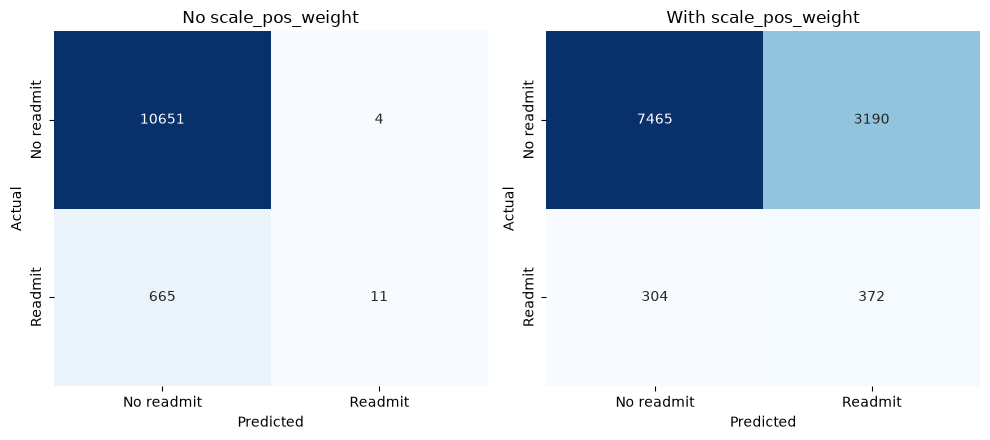

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, preds, title in zip(axes, [naive_preds, weighted_preds], ["No scale_pos_weight", "With scale_pos_weight"]):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No readmit", "Readmit"],
                yticklabels=["No readmit", "Readmit"], ax=ax, cbar=False)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)
plt.tight_layout()
plt.savefig("figures/naive_vs_weighted.png", dpi=150)
plt.show()



The difference is obvious once you see both confusion matrices side by
side. The naive model's bottom row, the actual readmissions, is almost
entirely predicted as the wrong class. The weighted model misses more on
the top row in exchange, more false alarms on patients who were not
actually readmitted, but it is now actually doing the job we built it
for, catching patients who come back.



## 8. Classification results

With an imbalanced problem like this one, accuracy is close to useless
on its own. A model that always predicts no readmission would already be
right about 94 percent of the time. Instead we look at precision,
recall, and two area under the curve scores: ROC AUC and PR AUC.

PR AUC is the more honest number here. For a rare outcome, it should be
judged against the baseline rate, not against 1.0. Our baseline rate is
about 0.06, so a PR AUC of 0.14 is roughly a two times lift over just
guessing at random.


In [15]:

from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve,
)

proba = model.predict_proba(X_test)[:, 1]
preds = (proba >= 0.5).astype(int)

roc_auc = roc_auc_score(y_test, proba)
pr_auc = average_precision_score(y_test, proba)
print(f"ROC AUC: {roc_auc:.4f}")
print(f"PR AUC: {pr_auc:.4f} (baseline rate is {y_test.mean():.4f})")
print()
print(classification_report(y_test, preds))


ROC AUC: 0.6842
PR AUC: 0.1423 (baseline rate is 0.0597)

              precision    recall  f1-score   support

           0       0.96      0.70      0.81     10655
           1       0.10      0.55      0.18       676

    accuracy                           0.69     11331
   macro avg       0.53      0.63      0.49     11331
weighted avg       0.91      0.69      0.77     11331



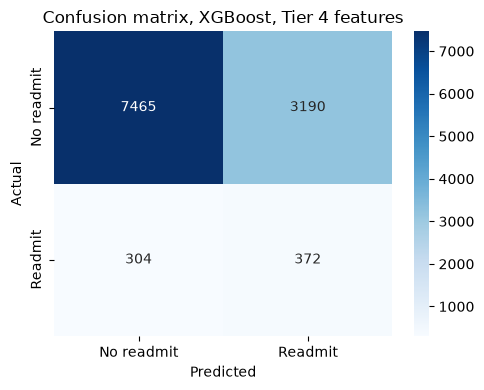

In [16]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, preds)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No readmit", "Readmit"],
            yticklabels=["No readmit", "Readmit"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion matrix, XGBoost, Tier 4 features")
plt.tight_layout()
plt.savefig("figures/confusion_matrix_xgb.png", dpi=150)
plt.show()



At the default 0.5 threshold, the model catches a little over half of
true readmissions. Precision is low in absolute terms, under 11 percent,
but remember the baseline rate is only 6 percent, so this is still a
real lift, not noise. For a triage use case where a false positive just
means an extra follow up call and a false negative means a missed at
risk patient, leaning toward higher recall at the cost of precision is a
reasonable tradeoff, not a flaw in the model.



## 9. Visualizing results

ROC and precision recall curves show how the tradeoff changes as we move
the decision threshold up or down, instead of looking at just one point
on that curve.


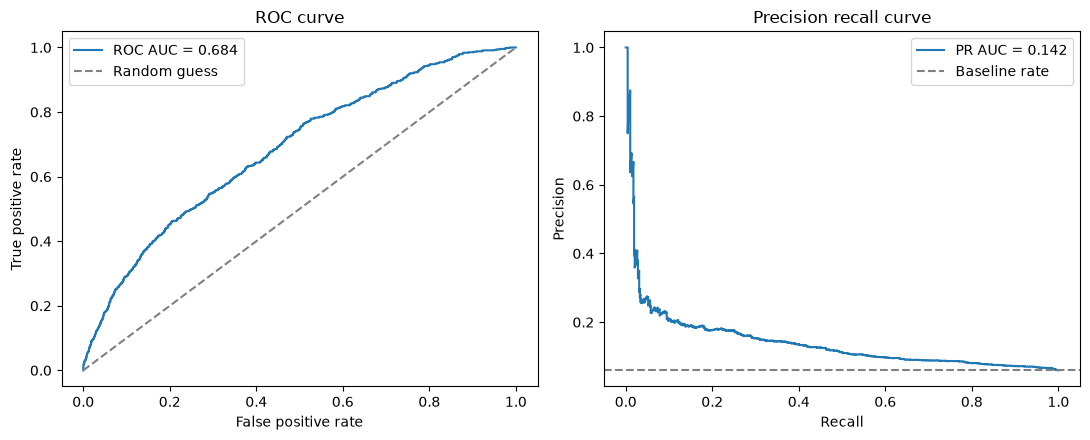

In [17]:

fpr, tpr, _ = roc_curve(y_test, proba)
precision, recall, _ = precision_recall_curve(y_test, proba)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve")
axes[0].legend()

axes[1].plot(recall, precision, label=f"PR AUC = {pr_auc:.3f}")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Baseline rate")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision recall curve")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/roc_pr_curves.png", dpi=150)
plt.show()



Notice how much more dramatic the gap looks on the precision recall
plot compared to the ROC plot. ROC AUC can look deceptively good on an
imbalanced problem because it includes true negatives, which are easy to
get right when 94 percent of the data is negative. This is exactly why
we lead with PR AUC for this kind of problem.


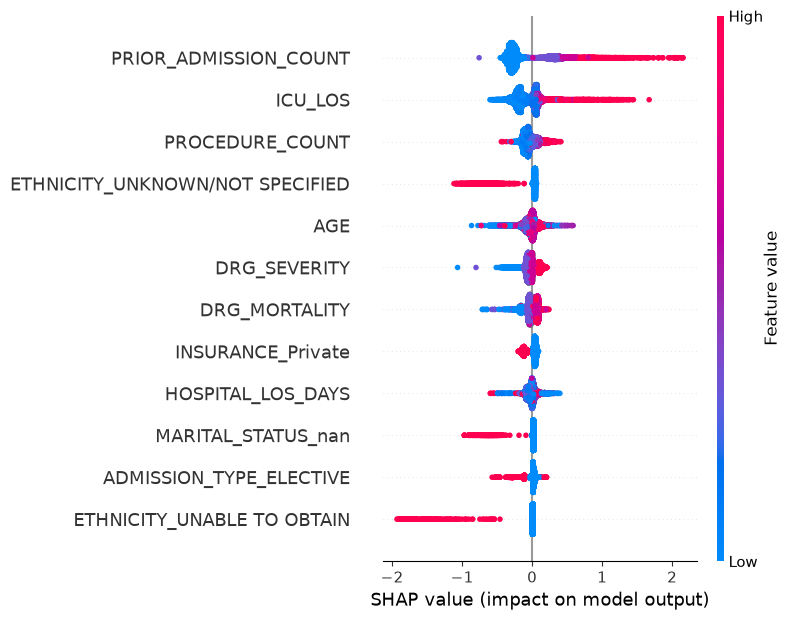

In [18]:

import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=False, max_display=12)
plt.tight_layout()
plt.savefig("figures/shap_summary.png", dpi=150)
plt.show()



This plot shows which features push a prediction toward readmission
(red, high feature value, pushed right) or away from it (blue), for
every row in the test set at once. Prior admission count stands out
clearly here, which matches the known research on this topic, and it
matches what we are about to see in the feature importance ranking too.



## 10. Back to feature selection, now with a trained model

Now that we have a model, we can rank every individual feature by how
much it actually contributed, instead of just thinking about which tier
it came from.


In [19]:

importances = pd.Series(model.feature_importances_, index=X_full.columns).sort_values(ascending=False)
print("Top 15 features by importance:")
print(importances.head(15))
print()
print("Bottom 10 features by importance:")
print(importances.tail(10))


Top 15 features by importance:
PRIOR_ADMISSION_COUNT               0.115459
HAD_ICU_STAY                        0.065345
CHAPTER_Perinatal Conditions        0.046029
ETHNICITY_UNKNOWN/NOT SPECIFIED     0.036046
MARITAL_STATUS_nan                  0.032222
ICU_LOS                             0.030090
PROCEDURE_COUNT                     0.029406
INSURANCE_Private                   0.027421
ADMISSION_TYPE_ELECTIVE             0.024186
DRG_MORTALITY                       0.023362
ETHNICITY_BLACK/AFRICAN AMERICAN    0.020263
CHAPTER_Injury & Poisoning          0.019837
INSURANCE_Government                0.018673
ETHNICITY_UNABLE TO OBTAIN          0.018443
DRG_SEVERITY                        0.018430
dtype: float32

Bottom 10 features by importance:
ETHNICITY_HISPANIC/LATINO - CENTRAL AMERICAN (OTHER)    0.0
ETHNICITY_HISPANIC/LATINO - PUERTO RICAN                0.0
ETHNICITY_CARIBBEAN ISLAND                              0.0
ETHNICITY_WHITE - EASTERN EUROPEAN                      0.0
ETHN


Prior admission count is the single most important feature by a wide
margin, more than double the next one. At the bottom of the list, every
least useful feature is a rare ethnicity category. One hot encoding a
column with this many distinct values creates a lot of sparse columns,
and most of them end up carrying almost no weight.

A natural question is whether we can drop the weakest half of these
features without losing much. Let's test that directly instead of
guessing.


In [20]:

keep_n = len(importances) // 2
top_features = importances.head(keep_n).index.tolist()

X_train_top = X_train[top_features]
X_test_top = X_test[top_features]

model_top = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42,
)
model_top.fit(X_train_top, y_train)
proba_top = model_top.predict_proba(X_test_top)[:, 1]

print(f"Full feature set, {X_full.shape[1]} features: ROC AUC {roc_auc:.4f}, PR AUC {pr_auc:.4f}")
print(f"Top half only, {keep_n} features: ROC AUC {roc_auc_score(y_test, proba_top):.4f}, "
      f"PR AUC {average_precision_score(y_test, proba_top):.4f}")


Full feature set, 92 features: ROC AUC 0.6842, PR AUC 0.1423
Top half only, 46 features: ROC AUC 0.6802, PR AUC 0.1409



Cutting the feature set in half barely moves either score. That is a
real, practical result. It means we could ship a simpler model with half
the columns and lose almost nothing, which matters in a real system
where every extra column is something you have to collect, store, and
maintain.



## 11. Trying a few engineered features

A common next step in feature engineering is to combine two existing
features into a new one, hoping the combination captures something
neither one does on its own. We tried three: ICU time as a fraction of
total stay, procedures per day of stay, and prior admissions divided by
age.


In [21]:

cohort_enriched = cohort.copy()
cohort_enriched["ICU_LOS_FRACTION"] = cohort_enriched["ICU_LOS"] / cohort_enriched["HOSPITAL_LOS_DAYS"].clip(lower=0.1)
cohort_enriched["PROCEDURES_PER_DAY"] = cohort_enriched["PROCEDURE_COUNT"] / cohort_enriched["HOSPITAL_LOS_DAYS"].clip(lower=0.1)
cohort_enriched["PRIOR_ADMITS_PER_AGE_YEAR"] = cohort_enriched["PRIOR_ADMISSION_COUNT"] / cohort_enriched["AGE"].clip(lower=1)

TIER_5 = TIER_4 + ["ICU_LOS_FRACTION", "PROCEDURES_PER_DAY", "PRIOR_ADMITS_PER_AGE_YEAR"]
X5 = pd.get_dummies(cohort_enriched[TIER_5], columns=CATEGORICAL_COLS, dummy_na=True)
X_train5, X_test5, y_train5, y_test5 = train_test_split(X5, y, test_size=0.25, stratify=y, random_state=42)

model5 = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42,
)
model5.fit(X_train5, y_train5)
proba5 = model5.predict_proba(X_test5)[:, 1]

print(f"Without engineered features: ROC AUC {roc_auc:.4f}, PR AUC {pr_auc:.4f}")
print(f"With engineered features:    ROC AUC {roc_auc_score(y_test5, proba5):.4f}, "
      f"PR AUC {average_precision_score(y_test5, proba5):.4f}")


Without engineered features: ROC AUC 0.6842, PR AUC 0.1423
With engineered features:    ROC AUC 0.6817, PR AUC 0.1343



The engineered features did not help, and performance actually dipped
slightly. This is a useful result, not a failed experiment. A boosted
tree model builds its predictions from a sequence of splits on the raw
features, so it can already approximate a ratio like procedures per day
by splitting on procedure count and length of stay separately. Manually
handing it the ratio does not give it new information it could not
already reach on its own. This kind of feature engineering tends to
matter much more for a linear model, which cannot represent an
interaction at all unless you give it one directly. We will see that
point again in the next section.



## 12. Does scaling matter for a boosted tree model

We keep saying XGBoost does not need feature scaling. Let's actually
check that instead of just asserting it.


In [22]:

from sklearn.preprocessing import StandardScaler

scaler_check = StandardScaler()
X_train_scaled = pd.DataFrame(scaler_check.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler_check.transform(X_test), columns=X_test.columns, index=X_test.index)

model_scaled = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42,
)
model_scaled.fit(X_train_scaled, y_train)
proba_scaled = model_scaled.predict_proba(X_test_scaled)[:, 1]

print(f"Unscaled: ROC AUC {roc_auc:.4f}, PR AUC {pr_auc:.4f}")
print(f"Scaled:   ROC AUC {roc_auc_score(y_test, proba_scaled):.4f}, PR AUC {average_precision_score(y_test, proba_scaled):.4f}")


Unscaled: ROC AUC 0.6842, PR AUC 0.1423
Scaled:   ROC AUC 0.6842, PR AUC 0.1423



Same result either way. A tree splits on whether a value is above or
below some threshold, and rescaling every value the same way does not
change which side of that threshold anything falls on.



## 13. Comparing every tier directly

We've described the tier by tier progression in words as we built each
one up. Let's actually compute it live, in one place, so the numbers are
reproducible rather than something we just asserted earlier.


In [23]:

from sklearn.model_selection import train_test_split

tiers = {
    "Tier 1: demographics only": TIER_1,
    "Tier 2: plus clinical context": TIER_2,
    "Tier 3: plus care intensity": TIER_3,
    "Tier 4: plus prior admissions": TIER_4,
}

comparison_rows = []
for tier_name, cols in tiers.items():
    cat_cols_here = [c for c in CATEGORICAL_COLS if c in cols]
    X_tier = pd.get_dummies(cohort[cols], columns=cat_cols_here, dummy_na=True)
    Xt_train, Xt_test, yt_train, yt_test = train_test_split(
        X_tier, y, test_size=0.25, stratify=y, random_state=42
    )

    neg_t, pos_t = (yt_train == 0).sum(), (yt_train == 1).sum()
    xgb_tier = XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.05,
        scale_pos_weight=neg_t / pos_t, eval_metric="logloss", random_state=42,
    )
    xgb_tier.fit(Xt_train, yt_train)
    xgb_proba = xgb_tier.predict_proba(Xt_test)[:, 1]

    comparison_rows.append({
        "Tier": tier_name,
        "ROC AUC": roc_auc_score(yt_test, xgb_proba),
        "PR AUC": average_precision_score(yt_test, xgb_proba),
    })

comparison_df = pd.DataFrame(comparison_rows)
print(comparison_df.round(4).to_string(index=False))


                         Tier  ROC AUC  PR AUC
    Tier 1: demographics only   0.6046  0.0979
Tier 2: plus clinical context   0.6431  0.1173
  Tier 3: plus care intensity   0.6510  0.1100
Tier 4: plus prior admissions   0.6842  0.1423



## 14. Where the real gain came from

Let's plot PR AUC, our primary metric for this imbalanced problem,
across all four tiers on one chart.


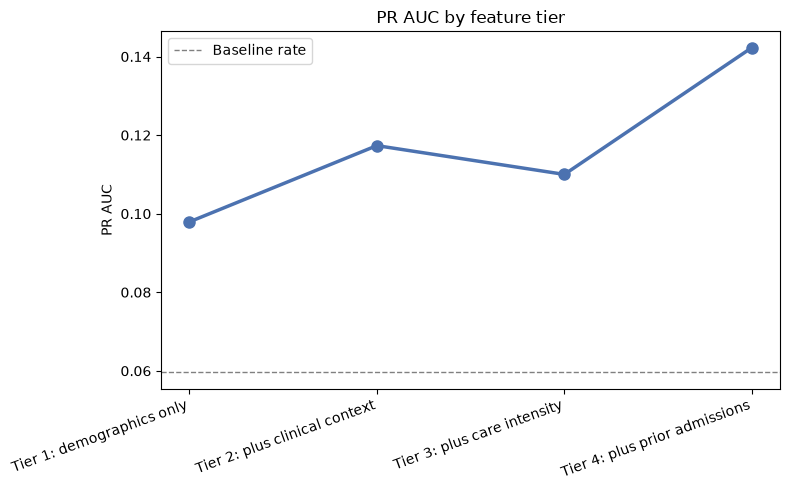

In [24]:

fig, ax = plt.subplots(figsize=(8, 5))
x_pos = range(len(comparison_df))
ax.plot(x_pos, comparison_df["PR AUC"], marker="o", linewidth=2.5, markersize=8, color="#4C72B0")
ax.axhline(y.mean(), linestyle="--", color="gray", linewidth=1, label="Baseline rate")
ax.set_xticks(list(x_pos))
ax.set_xticklabels(comparison_df["Tier"], rotation=20, ha="right")
ax.set_ylabel("PR AUC")
ax.set_title("PR AUC by feature tier")
ax.legend()
plt.tight_layout()
plt.savefig("figures/tier_comparison.png", dpi=150)
plt.show()



Look at the step from tier 3 to tier 4, adding prior admission count.
That single step is a bigger jump than the combined gain from tiers 1
through 3 put together. One feature, grounded in actual research about
hospital readmissions, outperformed an entire block of diagnosis,
severity, and care intensity features combined.

That is the real takeaway from this whole exercise. Knowing which
feature to add mattered more than anything else we tried, more than
engineering new ratios, more than tuning how much data we fed the model.



## 15. Conclusion

We set out to predict 30 day readmission using routine EHR data, and
ended up with a model that performs in a believable, modest range. A
ROC AUC around 0.68 and a PR AUC a little over twice the baseline rate
is in the same neighborhood as LACE, a real clinical risk score hospitals
use today, not a toy result.

The most useful lesson here is not about boosting itself. It is that the
biggest gains came from knowing which feature to add, not from adding
more complexity. Diagnosis, severity, and prior admission history did
almost all the work. Detailed ICU and procedure data added very little
once severity was already in the model, and manually engineered ratio
features did not help a tree based model at all. For a hospital deciding
where to invest in data infrastructure, that is a genuinely useful
finding: you do not necessarily need an expensive real time ICU data
pipeline to get most of the benefit. You need the basics, plus a
patient's own history, which most systems already have.

A natural next step would be to pull in the discharge summary text
itself using a tool like medspacy, since things like living situation,
medication complexity, and follow up planning show up in that text and
not in any structured column. We chose not to build that out here so the
imbalanced classification story stayed the main focus, but it is a
reasonable direction for anyone picking this up next.
